
# ROLL NUMBER: >>>>>>>>>>>>>>>

# Foundations of Vision and Language — Individual Mini CV Project (20 Marks)

# 10 Marks for coding and 10 marks for analysis

## Effect of Blur and Sharpening on Object Detection

- **Dataset:** COCO128
- **Model:** Pretrained YOLO11n
- **Platform:** Google Colab
- **Training:** Not required

### What this notebook provides
- package installation,
- COCO128 download,
- pretrained YOLO11n loading,
- dataset paths.

### What you must do
1. **Stage 1 — Baseline:** evaluate YOLO11n on the original COCO128 images.
2. **Stage 2 — Blur:** create a Gaussian-blurred version of the same images and evaluate again.
3. **Stage 3 — Sharpening:** sharpen the blurred images and evaluate again.
4. **Stage 4 — Analysis:** compare the three stages.

The experimental code for Stages 1–3 is intentionally left for you to complete.


## Setup 1 — Install Packages

In [2]:
!pip -q install -U ultralytics pyyaml

zsh:1: command not found: pip


## Setup 2 — Download COCO128

In [3]:
from pathlib import Path
import urllib.request
import zipfile
import os

# Google Colab → /content/datasets
# Local/Jupyter/GPU server → ~/fvl_datasets
if Path("/content").exists() and os.access("/content", os.W_OK):
    DATA_ROOT = Path("/content/datasets")
else:
    DATA_ROOT = Path.cwd() / "fvl_datasets"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

zip_path = DATA_ROOT / "coco128.zip"
dataset_dir = DATA_ROOT / "coco128"

if not dataset_dir.exists():
    url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"

    print("Downloading COCO128 to:", zip_path)
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_ROOT)

    print("Download and extraction complete.")
else:
    print("COCO128 already exists.")

print("Dataset ready at:", dataset_dir)
print("Images:", dataset_dir / "images" / "train2017")
print("Labels:", dataset_dir / "labels" / "train2017")

COCO128 already exists.
Dataset ready at: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_datasets/coco128
Images: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_datasets/coco128/images/train2017
Labels: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_datasets/coco128/labels/train2017


## Setup 3 — Load Pretrained YOLO11n

In [4]:
PROJECT_ROOT = Path('/fvl_project')
from pathlib import Path
import os

if Path("/content").exists() and os.access("/content", os.W_OK):
    PROJECT_ROOT = Path("/content/fvl_project")
else:
    PROJECT_ROOT = Path.cwd() / "fvl_project"

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)


Project folder: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project



# Stage 1 — Baseline on Original Images

### Your task
1. Prepare a dataset YAML that points to the original COCO128 images and labels.
2. Run `model.val(...)` using the pretrained YOLO11n model.
3. Record only these four metrics:
   - Precision
   - Recall
   - mAP@0.5
   - mAP@0.5:0.95
4. Save at least **3 prediction examples**.


In [5]:
#Create the Dataset Yaml

from pathlib import Path
import yaml
from ultralytics import YOLO


#check if the images are present

assert (dataset_dir/"images"/"train2017").is_dir(), "Images  folder not found, please download"
assert(dataset_dir/"labels"/"train2017").is_dir(), "Labels  folder not found, please download"


model = YOLO("yolo11n.pt")

dataset_config ={
    "path" :str(dataset_dir),
    "train":"images/train2017",
    "val":"images/train2017",
    "names":model.names

}

#Write dataset configuration file
yaml_path = PROJECT_ROOT/"coco128_original.yaml"

with yaml_path.open("w",encoding="utf-8") as file:
    yaml.safe_dump(dataset_config,file,sort_keys=False)


print("Dataset Yaml Created:",yaml_path,"\n")
print(yaml_path.read_text())

Dataset Yaml Created: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/coco128_original.yaml 

path: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_datasets/coco128
train: images/train2017
val: images/train2017
names:
  0: person
  1: bicycle
  2: car
  3: motorcycle
  4: airplane
  5: bus
  6: train
  7: truck
  8: boat
  9: traffic light
  10: fire hydrant
  11: stop sign
  12: parking meter
  13: bench
  14: bird
  15: cat
  16: dog
  17: horse
  18: sheep
  19: cow
  20: elephant
  21: bear
  22: zebra
  23: giraffe
  24: backpack
  25: umbrella
  26: handbag
  27: tie
  28: suitcase
  29: frisbee
  30: skis
  31: snowboard
  32: sports ball
  33: kite
  34: baseball bat
  35: baseball glove
  36: skateboard
  37: surfboard
  38: tennis racket
  39: bottle
  40: wine glass
  41: cup
  42: fork
  43: knife
  44: spoon
  45: bowl
  46: banana
  47: apple
  48: sandwich
  49: orange
  50: broccoli
  51: carrot
  52: hot dog
  53: pizza
  54: donut
  5

In [6]:
# 2. Run model.val(...).
import torch

if torch.cuda.is_available():
    device = 0 
elif torch.backends.mps.is_available():
   device = "mps"  
else:
    device="cpu"

print(f"Using device -> {device}")


metrics = model.val (
    data = str(yaml_path),
    split="val",
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    plots=True,
    project=str(PROJECT_ROOT),
    name="stage1_validation",
    exist_ok = True,
)




Using device -> mps
Ultralytics 8.4.182 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 154.3±53.1 MB/s, size: 54.8 KB)
val: Scanning /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 25.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.9it/s 8.2s0.5s
                   all        128        929       0.64      0.608      0.672      0.503
                person         61        254      0.771      0.717      0.786       0.54
               bicycle          3          6      0.377      0.167      0.422      0.267
                   car         12         46      0.623      0.196      0.238       0.16
            motorcycle          4          5      0.615          1 

In [7]:
# 3. Print the four required metrics.
print("\nStage1 - Baseline Metrics")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mp:.4f}")
#This measures mean Average Precision at an IoU threshold of 0.50.
print(f"mAP@0.5:       {metrics.box.map50:.4f}")
#This averages mAP over 10 IoU thresholds
print(f"mAP@0.5:0.95:  {metrics.box.map:.4f}")


Stage1 - Baseline Metrics
Precision: 0.6400
Recall: 0.6400
mAP@0.5:       0.6724
mAP@0.5:0.95:  0.5031



0: 640x640 3 bowls, 2 broccolis, 2.5ms
1: 640x640 1 giraffe, 2.5ms
2: 640x640 1 potted plant, 1 vase, 2.5ms
Speed: 42.3ms preprocess, 2.5ms inference, 28.7ms postprocess per image at shape (1, 3, 640, 640)
Image: 000000000009.jpg
Saved: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/stage1_predictions/000000000009_predictions.jpg
object detceted: 5
Object:<20 Confidence  Bounding box [x1, y1,x2, y2]
bowl                 [308.9, 0.7, 630.3, 236.8]
broccoli             [255.0, 229.6, 567.5, 476.0]
bowl                 [0.1, 189.6, 637.4, 474.4]
bowl                 [1.0, 7.7, 433.0, 393.4]
broccoli             [328.1, 410.0, 427.5, 479.6]


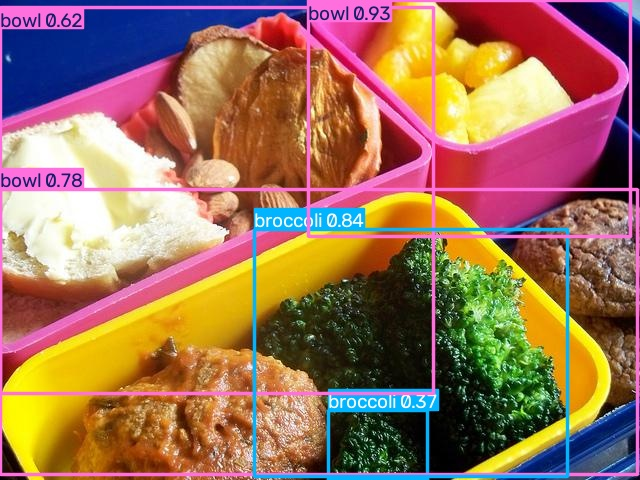

Image: 000000000025.jpg
Saved: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/stage1_predictions/000000000025_predictions.jpg
object detceted: 1
Object:<20 Confidence  Bounding box [x1, y1,x2, y2]
giraffe              [368.6, 63.7, 601.7, 358.0]


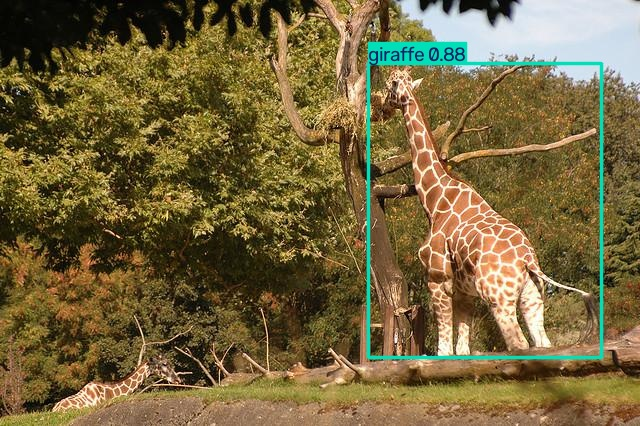

Image: 000000000030.jpg
Saved: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/stage1_predictions/000000000030_predictions.jpg
object detceted: 2
Object:<20 Confidence  Bounding box [x1, y1,x2, y2]
vase                 [237.8, 156.0, 407.9, 350.7]
potted plant         [203.4, 32.2, 459.9, 350.3]


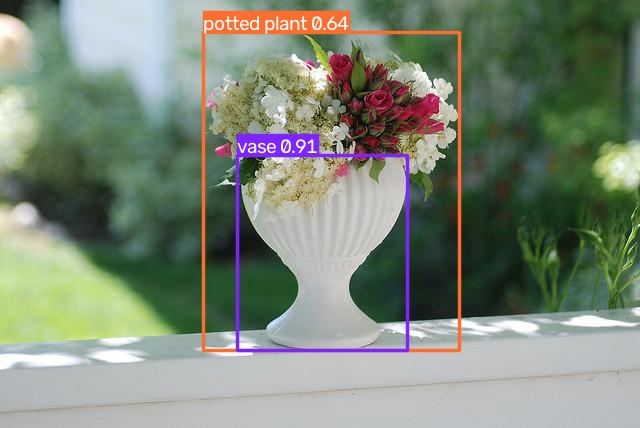

In [8]:
# 4. Save at least 3 prediction examples using model.predict(...).
from IPython.display import display
from PIL import Image

images_dir = dataset_dir/"images"/"train2017"

images_path = sorted(path for path in images_dir.iterdir()
                     if path.suffix.lower() in {".jpg",".jpeg",".png"})[:3]

output_dir = PROJECT_ROOT/"stage1_predictions"
output_dir.mkdir(parents=True, exist_ok=True)

results = model.predict(
    source=[str(path) for path in  images_path],
    device = device,
    imgsz=640,
    conf=0.25
)

for result in results:
    output_path = output_dir/f"{Path(result.path).stem}_predictions.jpg"
    result.save(filename=str(output_path))

    print(f"Image: {Path(result.path).name}")
    print(f"Saved: {output_path}")

    #Detection data moved to cpu
    boxes = result.boxes.cpu()

    print(f"object detceted: {len(boxes)}")

    if len(boxes)==0:
        print("No Object detected above the confidence threshold 0.25")

    else:
        print(
            f"{'Object:<20'} {'Confidence' :<12}"
            f"{'Bounding box [x1, y1,x2, y2]'}"
        )

        for class_id, confidence, coordinates in zip(boxes.cls.tolist(),
                                                     boxes.conf.tolist(), 
                                                     boxes.xyxy.tolist()):
            class_name =  result.names[int(class_id)]
            coordinates = [round(value,1) for value in coordinates]
            coordinates_text = ", ".join(f"{value:.1f}" for value in coordinates)

            print(f"{class_name:<20} [{coordinates_text}]")

    with Image.open(output_path) as image:
        display(image.copy())
            




# Stage 2 — Gaussian Blur

Create a blurred copy of **all COCO128 images**.

### Required blur setting
Use a **9 × 9 Gaussian kernel** with standard OpenCV Gaussian blur.

### Your task
1. Read every original image.
2. Apply Gaussian blur.
3. Save the blurred image with the same filename.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector on the blurred dataset.
6. Record the same four metrics.
7. Save at least **3 blurred prediction examples**.

Do not retrain or replace the detector.


In [12]:

# STAGE 2 — STUDENT CODE

import cv2
import shutil

BLURRED_ROOT = PROJECT_ROOT / 'blurred'

original_images_dir = dataset_dir / "images" / "train2017"
original_labels_dir = dataset_dir / "labels" / "train2017"

blurred_images_dir = BLURRED_ROOT / "images" / "train2017"
blurred_labels_dir = BLURRED_ROOT / "labels" / "train2017"


blurred_images_dir.mkdir(parents=True,exist_ok=True)
blurred_labels_dir.mkdir(parents=True,exist_ok=True)


image_paths = sorted(
    path for path in original_images_dir.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

assert original_images_dir.is_dir(), (
    f"Original images directory not found: {original_images_dir}"
)
assert original_labels_dir.is_dir(), (
    f"Original labels directory not found: {original_labels_dir}"
)

copied_labels = 0
missing_labels = []

for image_path in image_paths:
    # Always read the original image, not a previously blurred copy.
    image = cv2.imread(str(image_path))

    if image is None:
        raise RuntimeError(f"Could not read image: {image_path}")

    blurred_image = cv2.GaussianBlur(image, (9, 9), 0)

    # Save into images/train2017.
    output_image_path = blurred_images_dir / image_path.name

    if not cv2.imwrite(str(output_image_path), blurred_image):
        raise RuntimeError(f"Could not save image: {output_image_path}")

    source_label = original_labels_dir / f"{image_path.stem}.txt"
    output_label = blurred_labels_dir / source_label.name

    if source_label.is_file():
        shutil.copy2(source_label, output_label)
        copied_labels += 1
    else:
        # Preserve the original dataset's missing-label behavior.
        # Remove a stale output label if this cell was run previously.
        output_label.unlink(missing_ok=True)
        missing_labels.append(image_path.name)

# Create the blurred dataset YAML.
blurred_config = {
    "path": str(BLURRED_ROOT),
    "train": "images/train2017",
    "val": "images/train2017",
    "names": model.names,
}

blurred_yaml_path = PROJECT_ROOT / "coco128_blurred.yaml"

with blurred_yaml_path.open("w", encoding="utf-8") as file:
    yaml.safe_dump(blurred_config, file, sort_keys=False)

print("Blurred images saved:", len(image_paths))
print("Label files copied:", copied_labels)
print("Images without source label files:", len(missing_labels))
print("Dataset YAML:", blurred_yaml_path)

if missing_labels:
    print("\nImages without source label files:")
    for filename in missing_labels:
        print(" -", filename)




# TODO:
# 1. Create images/ and labels/ folders under BLURRED_ROOT.
# 2. Apply cv2.GaussianBlur(image, (9, 9), 0) to every image.
# 3. Copy the matching labels.
# 4. Create the blurred dataset YAML.
# 5. Run model.val(...).
# 6. Print the four required metrics.
# 7. Save at least 3 prediction examples.




Blurred images saved: 128
Label files copied: 126
Images without source label files: 2
Dataset YAML: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/coco128_blurred.yaml

Images without source label files:
 - 000000000250.jpg
 - 000000000508.jpg


In [14]:
# 5. Run model.val(...).
blurred_metrics = model.val(
    data=str(blurred_yaml_path),
    split="val",
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    plots=False,
    project=str(PROJECT_ROOT),
    name="stage2_validation",
    exist_ok=True,
)

Ultralytics 8.4.182 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 286.3±110.9 MB/s, size: 57.6 KB)
val: Scanning /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/blurred/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 59.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 11.1it/s 1.4s.2s
                   all        128        929      0.667      0.542      0.603      0.438
                person         61        254      0.773      0.588      0.694      0.479
               bicycle          3          6      0.197      0.167      0.169      0.109
                   car         12         46      0.594      0.109      0.164      0.104
            motorcycle          4          5      0.671          1      0.962      0.68

In [15]:
print("\nStage 2 — Blurred-image metrics")
print(f"Precision:     {blurred_metrics.box.mp:.4f}")
print(f"Recall:        {blurred_metrics.box.mr:.4f}")
print(f"mAP@0.5:       {blurred_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95:  {blurred_metrics.box.map:.4f}")


Stage 2 — Blurred-image metrics
Precision:     0.6666
Recall:        0.5421
mAP@0.5:       0.6029
mAP@0.5:0.95:  0.4381


Saved: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/stage2_predictions/000000000009_blurred_prediction.jpg
Saved: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/stage2_predictions/000000000025_blurred_prediction.jpg
Saved: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/stage2_predictions/000000000030_blurred_prediction.jpg


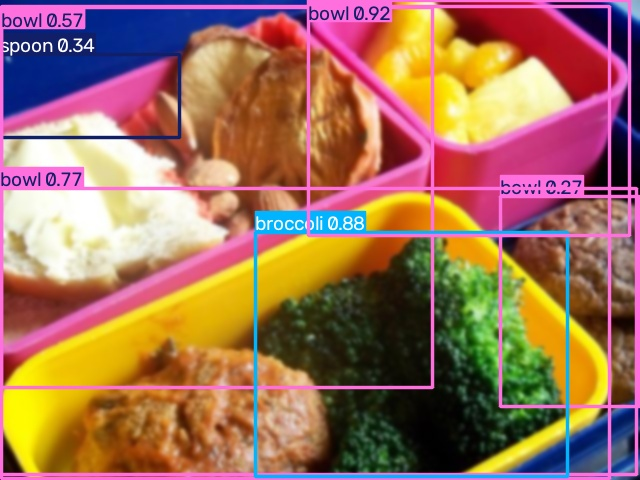

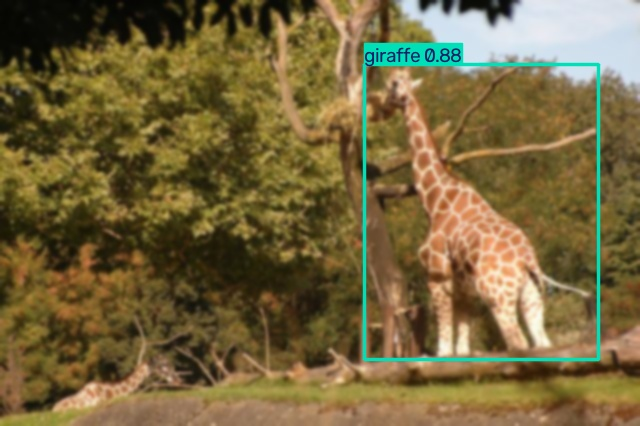

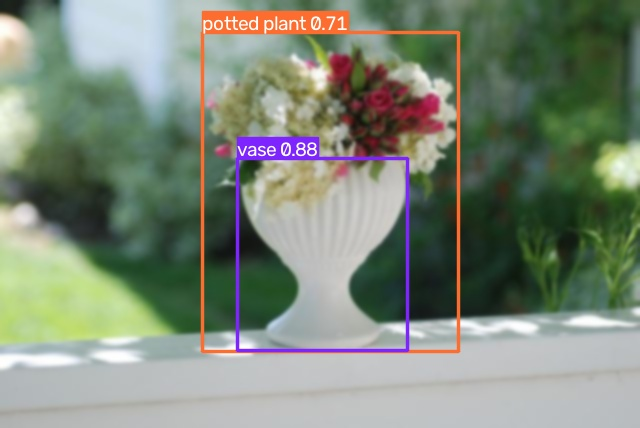

In [16]:
prediction_dir = PROJECT_ROOT / "stage2_predictions"
prediction_dir.mkdir(parents=True, exist_ok=True)

example_paths = [
    blurred_images_dir / path.name
    for path in image_paths[:3]
]

blurred_results = model.predict(
    source=[str(path) for path in example_paths],
    device=device,
    imgsz=640,
    conf=0.25,
    save=False,
    verbose=False,
)

for result in blurred_results:
    output_path = (
        prediction_dir / f"{Path(result.path).stem}_blurred_prediction.jpg"
    )
    result.save(filename=str(output_path))
    print("Saved:", output_path)

for image_path in example_paths:
    saved_path = (
        prediction_dir / f"{image_path.stem}_blurred_prediction.jpg"
    )

    with Image.open(saved_path) as image:
        display(image.copy())


# Stage 3 — Sharpen the Blurred Images

Apply **one sharpening method** to the Stage 2 blurred images.

You may use a standard sharpening kernel or unsharp masking. Keep the image size unchanged.

### Your task
1. Implement the sharpening operation yourself.
2. Apply it to every blurred image.
3. Save the sharpened images with the same filenames.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector again.
6. Record the same four metrics.
7. Save at least **3 sharpened prediction examples**.

Do not retrain or replace YOLO11n.


In [18]:
SHARPENED_ROOT = (PROJECT_ROOT / "sharpened").resolve()

# Write a separate Stage 3 dataset.
sharpened_images_dir = SHARPENED_ROOT / "images" / "train2017"
sharpened_labels_dir = SHARPENED_ROOT / "labels" / "train2017"

assert blurred_images_dir.is_dir(), "Run Stage 2 dataset creation first."
assert blurred_labels_dir.is_dir(), "Blurred labels directory not found."

sharpened_images_dir.mkdir(parents=True, exist_ok=True)
sharpened_labels_dir.mkdir(parents=True, exist_ok=True)

# 1. Implement one sharpening method.
def sharpen_image(image, amount=1.5, sigma=1.0):
    smoothed = cv2.GaussianBlur(image, (0, 0), sigma)

    return cv2.addWeighted(
        image, 1.0 + amount,
        smoothed, -amount,
        0,
    )


blurred_image_paths = sorted(
    path for path in blurred_images_dir.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

assert len(blurred_image_paths) >= 3, "Need at least 3 blurred images."

copied_labels = 0
missing_labels = []

for image_path in blurred_image_paths:
    image = cv2.imread(str(image_path))

    if image is None:
        raise RuntimeError(f"Could not read image: {image_path}")

    # 2. Sharpen the Stage 2 blurred image.
    sharpened_image = sharpen_image(image)

    output_image_path = sharpened_images_dir / image_path.name

    if not cv2.imwrite(str(output_image_path), sharpened_image):
        raise RuntimeError(f"Could not save image: {output_image_path}")

    # 3. Copy matching labels when they exist.
    source_label = blurred_labels_dir / f"{image_path.stem}.txt"
    output_label = sharpened_labels_dir / source_label.name

    if source_label.is_file():
        shutil.copy2(source_label, output_label)
        copied_labels += 1
    else:
        output_label.unlink(missing_ok=True)
        missing_labels.append(image_path.name)


# 4. Create the sharpened dataset YAML.
sharpened_config = {
    "path": str(SHARPENED_ROOT),
    "train": "images/train2017",
    "val": "images/train2017",
    "names": model.names,
}

sharpened_yaml_path = PROJECT_ROOT / "coco128_sharpened.yaml"

with sharpened_yaml_path.open("w", encoding="utf-8") as file:
    yaml.safe_dump(sharpened_config, file, sort_keys=False)

print("Sharpened images:", len(blurred_image_paths))
print("Labels copied:", copied_labels)
print("Images without label files:", len(missing_labels))
print("Dataset YAML:", sharpened_yaml_path)

Sharpened images: 128
Labels copied: 126
Images without label files: 2
Dataset YAML: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/coco128_sharpened.yaml


In [20]:
sharpened_metrics = model.val(
    data=str(sharpened_yaml_path),
    split="val",
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    plots=False,
    project=str(PROJECT_ROOT),
    name="stage3_validation",
    exist_ok=True,
)


Ultralytics 8.4.182 🚀 Python-3.14.3 torch-2.14.1 MPS (Apple M5)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1250.4±585.2 MB/s, size: 60.8 KB)
val: Scanning /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/sharpened/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 41.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 10.4it/s 1.5s.2ss
                   all        128        929       0.66      0.532      0.614       0.45
                person         61        254      0.807      0.614      0.725      0.496
               bicycle          3          6      0.166      0.167      0.103     0.0733
                   car         12         46      0.671      0.133      0.168      0.113
            motorcycle          4          5      0.684          1      0.995      

In [21]:
print("\nStage 3 — Sharpened Metrics")
print(f"Precision:     {sharpened_metrics.box.mp:.4f}")
print(f"Recall:        {sharpened_metrics.box.mr:.4f}")
print(f"mAP@0.5:       {sharpened_metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95:  {sharpened_metrics.box.map:.4f}")


Stage 3 — Sharpened Metrics
Precision:     0.6597
Recall:        0.5317
mAP@0.5:       0.6138
mAP@0.5:0.95:  0.4498


Saved: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/stage3_predictions/000000000009_sharpened_prediction.jpg
Saved: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/stage3_predictions/000000000025_sharpened_prediction.jpg
Saved: /Users/anoopkrishnan/Documents/projects/FoVl-assignment3/fvl_project/stage3_predictions/000000000030_sharpened_prediction.jpg


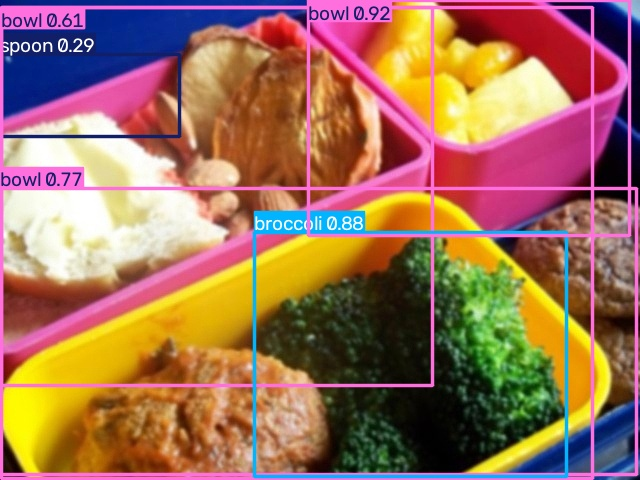

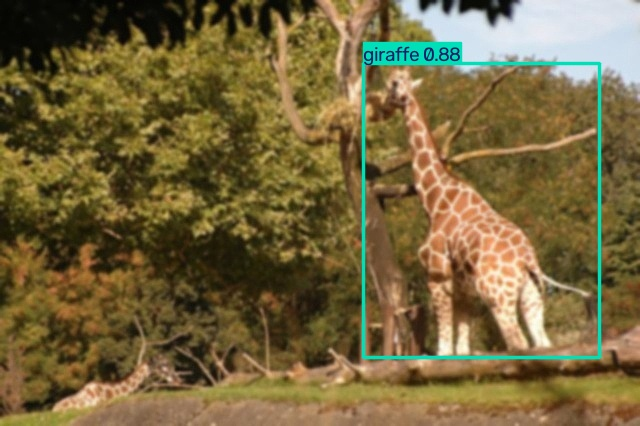

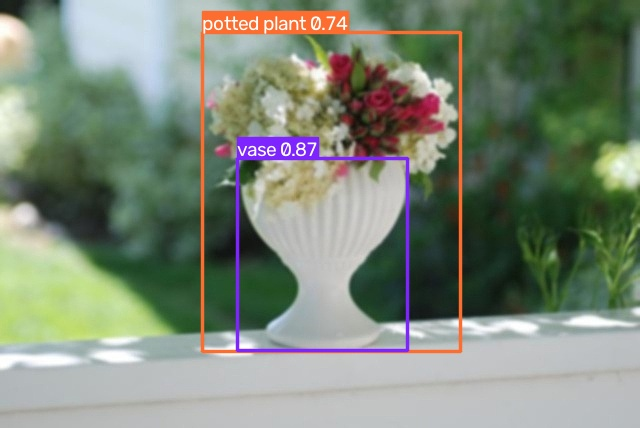

In [22]:
prediction_dir = PROJECT_ROOT / "stage3_predictions"
prediction_dir.mkdir(parents=True, exist_ok=True)

example_paths = [
    sharpened_images_dir / path.name
    for path in blurred_image_paths[:3]
]

sharpened_results = model.predict(
    source=[str(path) for path in example_paths],
    device=device,
    imgsz=640,
    conf=0.25,
    save=False,
    verbose=False,
)

for result in sharpened_results:
    output_path = (
        prediction_dir
        / f"{Path(result.path).stem}_sharpened_prediction.jpg"
    )

    result.save(filename=str(output_path))
    print("Saved:", output_path)

for image_path in example_paths:
    saved_path = (
        prediction_dir
        / f"{image_path.stem}_sharpened_prediction.jpg"
    )

    with Image.open(saved_path) as image:
        display(image.copy())

In [ ]:

# STAGE 3 — STUDENT CODE

SHARPENED_ROOT = PROJECT_ROOT / 'sharpened'

# TODO:
# 1. Implement one sharpening method.
# 2. Apply it to every blurred image.
# 3. Copy the matching labels.
# 4. Create the sharpened dataset YAML.
# 5. Run model.val(...).
# 6. Print the four required metrics.
# 7. Save at least 3 prediction examples.





# Stage 4 — Final Results - 10 Marks (Code, Results, Prediction Examples)

Enter your final values in the table below and the **values must be upto 4 decimal points.**

| Stage | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---:|---:|---:|---:|
| Original / Baseline | 0.6400| 0.6400 | 0.6724 | 0.5031 |
| Gaussian Blur | 0.6666 | 0.5421 | 0.6029 | 0.4381 |
| Sharpened | 0.6597 | 0.5317 | 0.6138 | 0.4498 |

## Analysis — 10 Marks (in points, Max 4 points for each)

### A. Effect of blur — 3 marks
What changed from Stage 1 to Stage 2? Use your actual metric values and prediction examples.

### B. Why sharpening? — 2 marks
What sharpening method did you use, and why can it help after blur?

### C. Did sharpening help? — 4 marks
Compare Stage 2 and Stage 3. What improved? What did not improve? Did any metric become worse? Use your actual values and examples.

### D. Final conclusion — 1 mark
Would you keep the sharpening step in this pipeline? Explain in no more than 100 words.






# Submission

Submit:
1. Completed `.ipynb` with final results table and with at least 3 prediction examples from each stage: Original, Blurred, Sharpened
2. Google Form for Results, Prediction examples and Analysis submission

Use your roll number in every submitted filename.
Students are requested to submit in time 1 marks will be deducted per day for late submission

Deadline: Sun, 25 October 2026, 11:59 P.M.
